# 1. Introduction and Mathematical Problem

This notebook presents a simplified, self-contained educational implementation of selected ideas from:

> **E. Devereux and A. Datta**, *"Quantum algorithms for solving a drift-diffusion equation: a complexity analysis"*, Phys. Rev. A **112**, 042419 (2025) [`arXiv:2505.21221v2`].

Our goal is to follow a single, transparent progression across **three methods** solving the exact same one-dimensional (1D) discrete drift-diffusion problem:

$$
\boxed{\text{Direct time evolution} \longrightarrow \text{Classical FFT} \longrightarrow \text{Quantum QFT}}
$$

### Governing Partial Differential Equation (PDE)

We solve the 1D drift-diffusion equation for a probability density $p(x, t)$ on a periodic spatial domain $x \in [-L, L)$ of length $2L$:

$$
\frac{\partial p}{\partial t} = a\frac{\partial p}{\partial x} + D\frac{\partial^2 p}{\partial x^2},
$$

where:
- $p(x, t) \ge 0$ is the probability density satisfying $\int_{-L}^{L} p(x, t)\,dx = 1$,
- $a > 0$ is the constant drift coefficient,
- $D > 0$ is the constant diffusion coefficient,
- $p(-L, t) = p(L, t)$ enforces periodic spatial boundary conditions.

### Sign Convention

Writing $+a \frac{\partial p}{\partial x}$ on the right-hand side is equivalent to the advection-diffusion form $\frac{\partial p}{\partial t} + (-a)\frac{\partial p}{\partial x} = D\frac{\partial^2 p}{\partial x^2}$, which corresponds to advection velocity $v = -a$. Consequently, when **$a > 0$**, the Gaussian centre moves towards **decreasing $x$**:

$$
\mu_t = x_0 - at.
$$

### Overview of the Three Methods
1. **Method 1 — Classical direct time evolution:** Forward-time, centred-space (FTCS) finite differences repeatedly applying the $N \times N$ circulant matrix $L$ for $n_t$ steps ($O(n_t N)$).
2. **Method 2 — Classical FFT diagonalisation:** Exploiting $L = F^\dagger \Lambda F$ to compute $\mathbf{p}(T) = F^\dagger \Lambda^{n_t} F \mathbf{p}(0)$ directly in Fourier space ($O(N \log N)$).
3. **Method 3 — Quantum Fourier transform (QFT) diagonalisation:** Implementing the exact same spectral evolution on $n = \log_2 N = 3$ spatial qubits and $1$ ancilla qubit using **Qiskit** and **Qiskit Aer**, via state preparation, QFT, an ancilla-assisted unitary dilation of $\Lambda^{n_t}$, inverse QFT, and postselection on $|0\rangle_{\text{anc}}$.

# 2. Parameters and Initial Gaussian

All numerical and physical parameters are defined together in the single setup cell below so that all three methods solve the **exact same discrete problem**.

### Choice of Grid and Stability Conditions

We discretise the periodic domain $[-L, L)$ with $L = 2.0$ (total length $2L = 4.0$) into $N = 8$ equally spaced grid points ($n = \log_2 N = 3$ qubits):

$$
\Delta x = \frac{2L}{N} = 0.5, \qquad x_i = -L + i\Delta x \quad (i = 0, 1, \dots, N-1).
$$

For forward-time, centred-space (FTCS) finite differences with time step $\Delta t = T / n_t$, the stencil coefficients are:

$$
c_0 = 1 - \frac{2D\Delta t}{\Delta x^2}, \qquad c_+ = \frac{a\Delta t}{2\Delta x} + \frac{D\Delta t}{\Delta x^2}, \qquad c_- = -\frac{a\Delta t}{2\Delta x} + \frac{D\Delta t}{\Delta x^2}.
$$

To satisfy explicit finite-difference stability and ensure that $c_0, c_+, c_- \ge 0$ (so they can also be interpreted as non-negative random-walk transition probabilities summing to $1$), we require:

$$
\frac{2D\Delta t}{\Delta x^2} \le 1 \quad \text{and} \quad \frac{a\Delta x}{2D} \le 1.
$$

### Periodic Wrapped Gaussian Initial Condition

Because the domain $[-L, L)$ is periodic, we construct the initial distribution as a **wrapped Gaussian** by summing periodic images shifted by multiples of the domain length $2L$:

$$
p(x, 0) = \sum_{m=-M_{\text{img}}}^{M_{\text{img}}} \frac{1}{\sqrt{2\pi\sigma_0^2}} \exp\left[-\frac{(x - x_0 + 2mL)^2}{2\sigma_0^2}\right],
$$

and normalise on the discrete grid so that $\sum_{i=0}^{N-1} p_i^0\,\Delta x = 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chisquare

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator

# ----------------------------------------------------------------------
# Central Parameter Block (all problem, grid, and simulation parameters)
# ----------------------------------------------------------------------
L_half = 2.0                        # Domain half-width L
x_min, x_max = -L_half, L_half      # Periodic spatial domain [-L, L)
domain_length = 2.0 * L_half        # Total domain length = 4.0

N = 8                               # Number of spatial grid points (2^n)
n_qubits = int(np.log2(N))          # Spatial qubits n = 3
dx = domain_length / N              # Spatial step Delta x = 0.5
x = x_min + np.arange(N) * dx       # Periodic spatial grid points x_i

a = 0.4                             # Drift coefficient (a > 0 drifts left)
D = 0.15                            # Diffusion coefficient (D > 0)
T = 1.5                             # Total simulation time
nt = 30                             # Number of discrete time steps
min_nt_cfl = max(1, int(np.ceil(2.0 * D * T / (dx ** 2))))
if nt < min_nt_cfl:
    print(f"[Auto-CFL] Increasing nt from {nt} to {min_nt_cfl} so 2*D*dt/dx^2 <= 1 for N={N}.")
    nt = min_nt_cfl
dt = T / nt                         # Time step Delta t = T / nt

x0 = 0.5                            # Initial Gaussian centre
sigma0 = 0.55                       # Initial Gaussian standard deviation
n_images = 6                        # Periodic image wrap summation cutoff

shots = 50_000                      # Shot count for finite-shot Qiskit Aer run
seed = 42                           # Deterministic simulator seed

# ----------------------------------------------------------------------
# FTCS Stencil Coefficients & Stability Check
# ----------------------------------------------------------------------
c0 = 1.0 - 2.0 * D * dt / (dx ** 2)
c_plus = a * dt / (2.0 * dx) + D * dt / (dx ** 2)
c_minus = -a * dt / (2.0 * dx) + D * dt / (dx ** 2)

diffusion_cfl = 2.0 * D * dt / (dx ** 2)
peclet_mesh = a * dx / (2.0 * D)

def wrapped_gaussian(x_eval, t):
    """Periodic wrapped Gaussian on [-L, L) with period = domain_length."""
    mu_t = x0 - a * t
    sigma_t = np.sqrt(sigma0 ** 2 + 2.0 * D * t)
    images = np.arange(-n_images, n_images + 1, dtype=float)
    shifted = np.asarray(x_eval, dtype=float)[:, None] - mu_t + images[None, :] * domain_length
    return np.sum(np.exp(-0.5 * (shifted / sigma_t) ** 2), axis=1) / (np.sqrt(2.0 * np.pi) * sigma_t)

# Initial distribution normalized so Riemann sum sum(p0) * dx == 1
p0_raw = wrapped_gaussian(x, t=0.0)
p0 = p0_raw / (np.sum(p0_raw) * dx)

print(f"Grid       : domain=[{x_min}, {x_max}), length={domain_length}, N={N} (n={n_qubits} qubits), dx={dx}")
print(f"Time/PDE   : a={a}, D={D}, T={T}, nt={nt}, dt={dt}, x0={x0}, sigma0={sigma0}")
print(f"Stencil    : c0={c0:.4f}, c+={c_plus:.4f}, c-={c_minus:.4f}, sum={c0 + c_plus + c_minus:.4f}")
print(f"Stability  : 2*D*dt/dx^2 = {diffusion_cfl:.4f} <= 1,  a*dx/(2*D) = {peclet_mesh:.4f} <= 1")
print(f"Initial p0 : sum(p0)*dx = {np.sum(p0) * dx:.12f}")

Grid       : domain=[-2.0, 2.0), length=4.0, N=8 (n=3 qubits), dx=0.5
Time/PDE   : a=0.4, D=0.15, T=1.5, nt=30, dt=0.05, x0=0.5, sigma0=0.55
Stencil    : c0=0.9400, c+=0.0500, c-=0.0100, sum=1.0000
Stability  : 2*D*dt/dx^2 = 0.0600 <= 1,  a*dx/(2*D) = 0.6667 <= 1
Initial p0 : sum(p0)*dx = 1.000000000000


# 3. Analytical Solution

On an infinite domain $(-\infty, \infty)$, the drift-diffusion PDE with Gaussian initial condition has the closed-form solution:

$$
\mu_t = x_0 - at, \qquad \sigma_t^2 = \sigma_0^2 + 2Dt,
$$

$$
p_{\infty}(x, t) = \frac{1}{\sqrt{2\pi\sigma_t^2}} \exp\left[-\frac{(x - \mu_t)^2}{2\sigma_t^2}\right].
$$

Because our discrete spatial domain $[-L, L)$ is periodic with period $2L$, we evaluate the **periodic wrapped Gaussian** obtained by summing periodic images separated by multiples of $2L$ (implemented in `wrapped_gaussian(x, t)` above). Normalising the wrapped Gaussian on the grid ($\sum_i p_i(T)\,\Delta x = 1$) gives the exact periodic analytical reference `p_exact_T` at $t = T$.

In [2]:
# Discrete analytical wrapped Gaussian at t = T (normalized on the N-point grid)
p_exact_T_raw = wrapped_gaussian(x, t=T)
p_exact_T = p_exact_T_raw / (np.sum(p_exact_T_raw) * dx)

# Fine spatial grid for smooth plotting of the analytical curves
x_fine = np.linspace(x_min, x_max, 400)
p_exact_0_fine = wrapped_gaussian(x_fine, t=0.0)
p_exact_T_fine = wrapped_gaussian(x_fine, t=T)

mu_T = x0 - a * T
sigma_T = np.sqrt(sigma0 ** 2 + 2.0 * D * T)
print(f"Analytical mean  : mu(0) = {x0:.3f}  -->  mu(T) = {mu_T:.3f}  (shifted left since a > 0)")
print(f"Analytical width : sigma(0) = {sigma0:.4f}  -->  sigma(T) = {sigma_T:.4f}")
print(f"Discrete norm    : sum(p_exact_T)*dx = {np.sum(p_exact_T) * dx:.12f}")

Analytical mean  : mu(0) = 0.500  -->  mu(T) = -0.100  (shifted left since a > 0)
Analytical width : sigma(0) = 0.5500  -->  sigma(T) = 0.8675
Discrete norm    : sum(p_exact_T)*dx = 1.000000000000


# 4. Classical Direct Time Evolution

Using forward-time, centred-space (FTCS) finite differences, the update at spatial index $i \in \{0, \dots, N-1\}$ and time index $k \in \{0, \dots, n_t - 1\}$ is:

$$
p_i^{k+1} = c_0 p_i^k + c_+ p_{i+1}^k + c_- p_{i-1}^k,
$$

with periodic indexing $(i \pm 1) \bmod N$. Writing $\mathbf{p}^k = (p_0^k, \dots, p_{N-1}^k)^T$, one time step is the matrix-vector product $\mathbf{p}^{k+1} = L\mathbf{p}^k$, where $L$ is the $N \times N$ circulant evolution matrix.

### Physical & Numerical Interpretation
- **Spatial index $i$:** labels the discrete grid point $x_i = -L + i\Delta x$.
- **Time index $k$:** labels the discrete time level $t_k = k\Delta t$.
- **Drift and diffusion:** because $a > 0$, we have $c_+ > c_-$, so each site receives slightly more mass from its right neighbour $x_{i+1}$ than from its left neighbour $x_{i-1}$, drifting the distribution towards decreasing $x$; simultaneously, $D > 0$ spreads mass outward to neighbouring sites, broadening the Gaussian and lowering its peak.
- **Why periodic indexing is required:** wrapping indices modulo $N$ enforces $p(-L, t) = p(L, t)$, conserves total probability ($\sum_i p_i^k \Delta x = 1$ because every column of $L$ sums to $c_0 + c_+ + c_- = 1$), and gives $L$ the circulant structure required by Fourier diagonalisation.
- **Computational complexity:** each of the $n_t$ steps applies a 3-point stencil across $N$ points, giving total cost **$O(n_t N)$**.

Below, **Figure 1** displays both spatial snapshots at selected intermediate times and the **full space-time solution $p(x, t)$** constructed exclusively from the direct time-evolution trajectory $\mathbf{p}^k = L^k \mathbf{p}^0$.

Mass conservation at t=T : sum(p_direct)*dx = 1.000000000000
L_inf error vs analytical : 0.026480


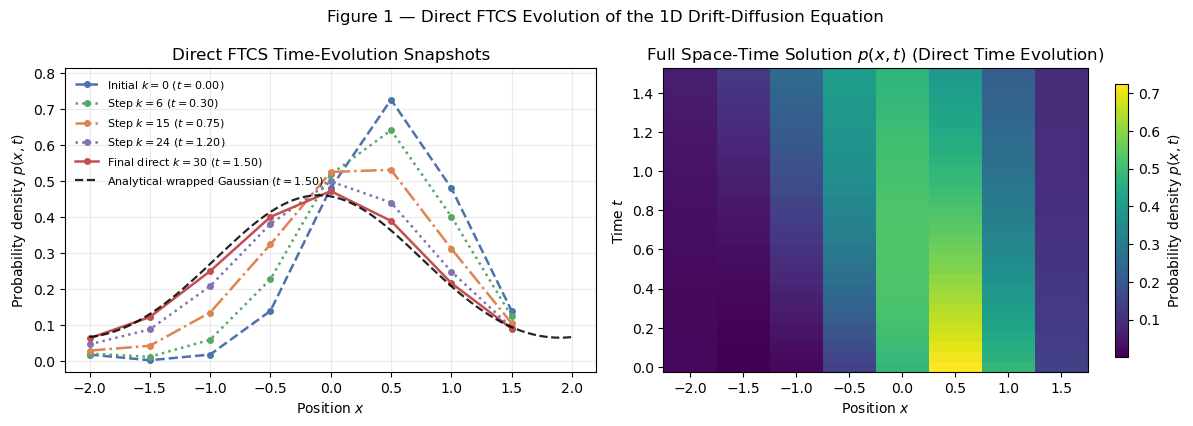

In [3]:
# Build N x N circulant spatial evolution matrix L with periodic indexing
idx = np.arange(N)
L_mat = np.zeros((N, N), dtype=float)
L_mat[idx, idx] = c0
L_mat[idx, (idx + 1) % N] = c_plus
L_mat[idx, (idx - 1) % N] = c_minus

# Direct time evolution: p^{k+1} = L p^k
p_history = np.zeros((nt + 1, N), dtype=float)
p_history[0] = p0.copy()
for k in range(nt):
    p_history[k + 1] = L_mat @ p_history[k]

p_direct = p_history[-1]
direct_err_inf = np.max(np.abs(p_direct - p_exact_T))
print(f"Mass conservation at t=T : sum(p_direct)*dx = {np.sum(p_direct) * dx:.12f}")
print(f"L_inf error vs analytical : {direct_err_inf:.6f}")

# Figure 1 — Direct evolution (snapshots + full space-time heatmap)
t_grid = np.linspace(0.0, T, nt + 1)
fig1, (ax1, ax1_map) = plt.subplots(1, 2, figsize=(12.2, 4.3))

snap_indices = sorted(set([0, nt // 5, nt // 2, (4 * nt) // 5, nt]))
snap_styles = [("--", "#4c72b0"), (":", "#55a868"), ("-.", "#dd8452"), (":", "#8172b3"), ("-", "#c44e52")]
for step, (ls, color) in zip(snap_indices, snap_styles):
    tag = "Initial " if step == 0 else ("Final direct " if step == nt else "Step ")
    ax1.plot(x, p_history[step], linestyle=ls, marker="o", markersize=4 if N <= 16 else 0, lw=1.8,
             color=color, label=f"{tag}$k={step}$ ($t={t_grid[step]:.2f}$)")

ax1.plot(x_fine, p_exact_T_fine, "k--", lw=1.6, alpha=0.85, label=f"Analytical wrapped Gaussian ($t={T:.2f}$)")
ax1.set_title("Direct FTCS Time-Evolution Snapshots")
ax1.set_xlabel("Position $x$")
ax1.set_ylabel("Probability density $p(x, t)$")
ax1.set_ylim(-0.03, max(0.80, float(np.max(p_history)) * 1.12))
ax1.grid(alpha=0.25)
ax1.legend(loc="upper left", frameon=False, fontsize=8)

im = ax1_map.pcolormesh(x, t_grid, p_history, shading="auto", cmap="viridis")
ax1_map.set_title(r"Full Space-Time Solution $p(x, t)$ (Direct Time Evolution)")
ax1_map.set_xlabel("Position $x$")
ax1_map.set_ylabel("Time $t$")
fig1.colorbar(im, ax=ax1_map, shrink=0.9, label="Probability density $p(x, t)$")

fig1.suptitle("Figure 1 — Direct FTCS Evolution of the 1D Drift-Diffusion Equation", fontsize=12)
plt.tight_layout()
plt.show()

# 5. Classical FFT Diagonalisation

Because $a$ and $D$ are constant and the boundary conditions are periodic, every row of $L$ is a cyclic shift of the row above it — $L$ is a **circulant matrix**. Plainly, discrete Fourier modes $e^{2\pi i j k / N}$ are exact eigenfunctions of cyclic spatial shifts, so the unitary discrete Fourier transform $F$ (with entries $F_{j,k} = \frac{1}{\sqrt{N}} e^{-2\pi i j k / N}$) diagonalises $L$:

$$
L = F^\dagger \Lambda F \implies \boxed{\mathbf{p}(T) = F^\dagger \Lambda^{n_t} F \mathbf{p}(0)}
$$

where $\Lambda = \operatorname{diag}(\lambda_0, \lambda_1, \dots, \lambda_{N-1})$ contains the exact discrete eigenvalues of our FTCS evolution matrix $L$:

$$
\lambda_j = 1 - \frac{4D\Delta t}{\Delta x^2}\sin^2\left(\frac{\pi j}{N}\right) + i\frac{a\Delta t}{\Delta x}\sin\left(\frac{2\pi j}{N}\right), \qquad j = 0, 1, \dots, N-1.
$$

Using the Fast Fourier Transform (FFT) and inverse FFT (`np.fft.fft` and `np.fft.ifft` with `norm="ortho"`), all $n_t$ time steps are collapsed into a single elementwise power $\lambda_j^{n_t}$ in Fourier space. Counting the FFT-based evolution itself (excluding any separately considered setup costs), the computational complexity is **$O(N \log N)$**.

Matrix diagonalisation check ||F^dag Lambda F - L||_inf = 6.75e-16
FFT vs Direct max abs diff (L_inf) = 9.44e-16
FFT vs Direct relative L2 error    = 1.94e-15


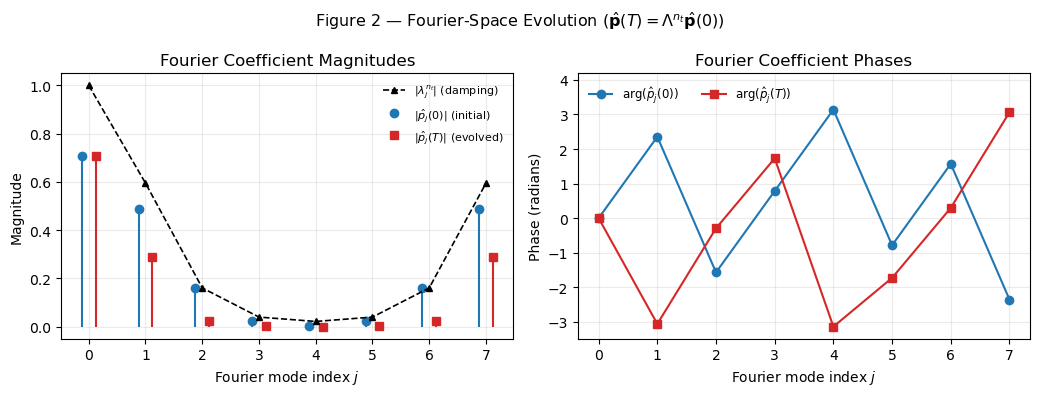

In [4]:
# Exact discrete eigenvalues of the FTCS circulant operator L
j_modes = np.arange(N)
lambda_j = (
    1.0
    - (4.0 * D * dt / (dx ** 2)) * (np.sin(np.pi * j_modes / N) ** 2)
    + 1j * (a * dt / dx) * np.sin(2.0 * np.pi * j_modes / N)
)
lambda_nt = lambda_j ** nt

# Verify L = F^dagger Lambda F numerically using the unitary DFT matrix F
F_dft = np.exp(-2j * np.pi * np.outer(j_modes, j_modes) / N) / np.sqrt(N)
diag_check_err = np.max(np.abs(F_dft.conj().T @ np.diag(lambda_j) @ F_dft - L_mat))

# 4-step Classical FFT evolution
# 1. Initial spatial distribution: p0
# 2. Initial Fourier coefficients: F p0
p_hat_0 = np.fft.fft(p0, norm="ortho")
# 3. Evolved Fourier coefficients: Lambda^{nt} F p0
p_hat_T = lambda_nt * p_hat_0
# 4. Reconstructed final spatial distribution: F^dagger Lambda^{nt} F p0
p_fft = np.fft.ifft(p_hat_T, norm="ortho").real

fft_vs_direct_inf = np.max(np.abs(p_fft - p_direct))
fft_vs_direct_rel_l2 = np.linalg.norm(p_fft - p_direct) / np.linalg.norm(p_direct)
print(f"Matrix diagonalisation check ||F^dag Lambda F - L||_inf = {diag_check_err:.2e}")
print(f"FFT vs Direct max abs diff (L_inf) = {fft_vs_direct_inf:.2e}")
print(f"FFT vs Direct relative L2 error    = {fft_vs_direct_rel_l2:.2e}")

# Figure 2 — Fourier-space evolution (magnitude and phase)
fig2, axes2 = plt.subplots(1, 2, figsize=(10.5, 4.0))

axes2[0].stem(j_modes - 0.12, np.abs(p_hat_0), linefmt="C0-", markerfmt="C0o", basefmt=" ", label="$|\\hat{p}_j(0)|$ (initial)")
axes2[0].stem(j_modes + 0.12, np.abs(p_hat_T), linefmt="C3-", markerfmt="C3s", basefmt=" ", label="$|\\hat{p}_j(T)|$ (evolved)")
axes2[0].plot(j_modes, np.abs(lambda_nt), "k^--", lw=1.2, markersize=5, label="$|\\lambda_j^{n_t}|$ (damping)")
axes2[0].set_title("Fourier Coefficient Magnitudes")
axes2[0].set_xlabel("Fourier mode index $j$")
axes2[0].set_ylabel("Magnitude")
axes2[0].set_xticks(j_modes)
axes2[0].grid(alpha=0.25)
axes2[0].legend(frameon=False, fontsize=8)

axes2[1].plot(j_modes, np.angle(p_hat_0), "o-", lw=1.5, color="C0", label="$\\arg(\\hat{p}_j(0))$")
axes2[1].plot(j_modes, np.angle(p_hat_T), "s-", lw=1.5, color="C3", label="$\\arg(\\hat{p}_j(T))$")
axes2[1].set_title("Fourier Coefficient Phases")
axes2[1].set_xlabel("Fourier mode index $j$")
axes2[1].set_ylabel("Phase (radians)")
axes2[1].set_xticks(j_modes)
axes2[1].set_ylim(-np.pi - 0.35, np.pi + 1.05)
axes2[1].grid(alpha=0.25)
axes2[1].legend(loc="upper left", ncol=2, frameon=False, fontsize=8.5)

fig2.suptitle("Figure 2 — Fourier-Space Evolution ($\\hat{\\mathbf{p}}(T) = \\Lambda^{n_t}\\hat{\\mathbf{p}}(0)$)", fontsize=11.5)
plt.tight_layout()
plt.show()

# 6. Quantum State Preparation

To implement Method 3 in **Qiskit**, we encode the $N = 8$ spatial grid values into $n = \log_2 N = 3$ qubits as a normalised quantum statevector:

$$
|\psi_0\rangle = \frac{1}{\|\mathbf{p}_0\|_2} \sum_{j=0}^{N-1} p_j^0 |j\rangle.
$$

### Key Properties of this Encoding
- **Why $L_2$ normalisation is required:** A pure quantum state must have unit Euclidean norm ($\langle\psi_0|\psi_0\rangle = \sum_j |\psi_{0,j}|^2 = 1$), whereas classical probability densities satisfy $\sum_j p_j^0\,\Delta x = 1$. We store `norm_p0` $= \|\mathbf{p}_0\|_2$ so we can undo this scaling when recovering the density at the end.
- **Amplitudes equal scaled density values (not square roots):** The basis amplitudes are proportional to $p_j^0$ themselves rather than $\sqrt{p_j^0}$, so linear operators ($F$, $K$, $F^\dagger$) act linearly on the probability density vector itself.

Below we use Qiskit's `prepare_state` instruction and verify the prepared state on `AerSimulator(method="statevector")`.

In [5]:
# Amplitude-encode the initial density p0 on n = 3 qubits
norm_p0 = float(np.linalg.norm(p0, ord=2))
psi0 = p0 / norm_p0

# Prepare |psi_0> using Qiskit's state-preparation instruction and simulate on Aer
sim_sv = AerSimulator(method="statevector")

qc_prep = QuantumCircuit(n_qubits)
qc_prep.prepare_state(psi0, range(n_qubits))
qc_prep_sv = qc_prep.copy()
qc_prep_sv.save_statevector()

psi0_qiskit = np.asarray(sim_sv.run(transpile(qc_prep_sv, sim_sv, optimization_level=0)).result().get_statevector(qc_prep_sv))
prep_err = np.max(np.abs(psi0_qiskit - psi0))
print(f"||p0||_2 = {norm_p0:.6f},  ||psi0||_2 = {np.linalg.norm(psi0_qiskit):.12f}")
print(f"State-preparation error vs target |psi0> : {prep_err:.2e}")

||p0||_2 = 1.012826,  ||psi0||_2 = 1.000000000000
State-preparation error vs target |psi0> : 8.33e-16


# 7. Qiskit QFT Circuit

Next, we apply the Quantum Fourier Transform (QFT) to the spatial register:

$$
|\psi_F\rangle = F|\psi_0\rangle.
$$

### Fourier Sign Convention and Qubit Ordering
In Method 2, `np.fft.fft(..., norm="ortho")` implements the unitary matrix $F_{j,k} = \frac{1}{\sqrt{N}} e^{-2\pi i j k / N}$, and `np.fft.ifft(..., norm="ortho")` implements $F^\dagger_{k,j} = \frac{1}{\sqrt{N}} e^{+2\pi i j k / N}$.

In Qiskit's little-endian qubit indexing ($|q_{n-1}\dots q_1 q_0\rangle$):
- Applying Hadamard (`h`), controlled-phase (`cp`) gates with angles **$-\pi/2^{t-c}$**, and bit-reversal `swap` gates implements **$F$** (matching `np.fft.fft(..., norm="ortho")`).
- Reversing that circuit with positive angles **$+\pi/2^{t-c}$** implements the inverse **$F^\dagger$** (matching `np.fft.ifft(..., norm="ortho")`).

We construct this explicit gate-level QFT circuit below and verify that its Qiskit Aer statevector matches the classical normalised FFT output $F|\psi_0\rangle$ to machine precision.

In [6]:
def add_qft(qc, qubits, inverse_sign=True):
    """Append n-qubit QFT (inverse_sign=True -> F matching np.fft.fft; False -> F^dagger)."""
    nq = len(qubits)
    if inverse_sign:
        for target in range(nq - 1, -1, -1):
            qc.h(qubits[target])
            for ctrl in range(target - 1, -1, -1):
                qc.cp(-np.pi / (2 ** (target - ctrl)), qubits[ctrl], qubits[target])
        for i in range(nq // 2):
            qc.swap(qubits[i], qubits[nq - 1 - i])
    else:
        for i in range(nq // 2):
            qc.swap(qubits[i], qubits[nq - 1 - i])
        for target in range(nq):
            for ctrl in range(target):
                qc.cp(np.pi / (2 ** (target - ctrl)), qubits[ctrl], qubits[target])
            qc.h(qubits[target])

# Apply QFT to |psi_0> and verify against classical unitary FFT
# (optimization_level=0 keeps SWAP gates in logical order for statevector inspection)
qc_qft_check = qc_prep.copy()
add_qft(qc_qft_check, list(range(n_qubits)), inverse_sign=True)
qc_qft_check.save_statevector()

psi_F_qiskit = np.asarray(sim_sv.run(transpile(qc_qft_check, sim_sv, optimization_level=0)).result().get_statevector(qc_qft_check))
psi_F_classical = np.fft.fft(psi0, norm="ortho")
qft_vs_fft_err = np.max(np.abs(psi_F_qiskit - psi_F_classical))

# Also verify round-trip QFT followed by IQFT recovers |psi_0>
qc_roundtrip = qc_prep.copy()
add_qft(qc_roundtrip, list(range(n_qubits)), inverse_sign=True)
add_qft(qc_roundtrip, list(range(n_qubits)), inverse_sign=False)
qc_roundtrip.save_statevector()
psi0_roundtrip = np.asarray(sim_sv.run(transpile(qc_roundtrip, sim_sv, optimization_level=0)).result().get_statevector(qc_roundtrip))
roundtrip_err = np.max(np.abs(psi0_roundtrip - psi0))

print(f"Qiskit QFT vs classical FFT max diff : {qft_vs_fft_err:.2e}")
print(f"QFT + IQFT round-trip error          : {roundtrip_err:.2e}")

Qiskit QFT vs classical FFT max diff : 5.24e-16
QFT + IQFT round-trip error          : 9.42e-16


# 8. Ancilla-Assisted Eigenvalue Evolution

In Fourier space, evolving for $n_t$ steps requires multiplying by the diagonal operator:

$$
H = \operatorname{diag}\!\left(\lambda_0^{n_t}, \lambda_1^{n_t}, \dots, \lambda_{N-1}^{n_t}\right).
$$

Because diffusion damps nonzero spatial frequencies ($|\lambda_j^{n_t}| < 1$ for $j \neq 0$), $H$ is **non-unitary** and cannot be implemented directly as a gate on the $3$ spatial qubits alone.

### Unitary Dilation Construction

We introduce one **ancilla qubit** (`anc`) and rescale $H$ into a contraction $K$ with singular values $\le 1$:

$$
\alpha = \max_j |\lambda_j^{n_t}|, \qquad K = \frac{H}{\alpha}.
$$

We then construct the $2N \times 2N$ ($16 \times 16$) unitary dilation:

$$
U = \begin{pmatrix}
K & \sqrt{I - K K^\dagger} \\
\sqrt{I - K^\dagger K} & -K^\dagger
\end{pmatrix},
$$

which embeds $K$ in the $|0\rangle_{\text{anc}}$ block:

$$
\boxed{\langle 0|_{\text{anc}} U |0\rangle_{\text{anc}} = K}
$$

**Basis consistency:** placing `anc` as the most significant qubit (index $3$ in `[x_0, x_1, x_2, anc]`) means basis indices $0 \dots N-1$ correspond to $|0\rangle_{\text{anc}} \otimes |j\rangle_{\text{space}}$, so the top-left $N \times N$ block of $U$ equals $K$.

**Scope & limitation of this small construction:** forming the explicit dense $2N \times 2N$ matrix $U$ is clear and exact for our $N = 8$ demonstration, but building dense matrices classically scales as $O(N^2)$ and does not scale to large grids; scalable quantum implementations instead synthesize diagonal contractions via coherent arithmetic and controlled ancilla rotations (as analysed in Devereux & Datta).

In [7]:
# Build the contraction K = H / alpha and its 1-ancilla unitary dilation U
H_diag = np.diag(lambda_nt)
alpha = float(np.max(np.abs(lambda_nt)))
K = H_diag / alpha

# Since K is diagonal with |K_jj| <= 1, sqrt(I - K K^dag) = sqrt(I - K^dag K) is diagonal
diag_comp = np.diag(np.sqrt(np.maximum(0.0, 1.0 - np.abs(np.diag(K)) ** 2)))
U_dilation = np.block([
    [K, diag_comp],
    [diag_comp, -K.conj().T]
])

unitarity_err = np.max(np.abs(U_dilation.conj().T @ U_dilation - np.eye(2 * N)))
block0_err = np.max(np.abs(U_dilation[:N, :N] - K))

print(f"Rescaling factor alpha             : {alpha:.10f}")
print(f"Unitarity check ||U^dag U - I||    : {unitarity_err:.2e}")
print(f"Ancilla-|0> block check ||U_00-K|| : {block0_err:.2e}")

Rescaling factor alpha             : 1.0000000000
Unitarity check ||U^dag U - I||    : 1.11e-16
Ancilla-|0> block check ||U_00-K|| : 0.00e+00


# 9. Qiskit Simulation and Postselection

Combining every piece yields the 4-qubit QFT solver circuit:

```text
x[0..2]: |0⟩ ─[ Prep |ψ₀⟩ ]─[  QFT (F)  ]─┤                ├─[ IQFT (F†) ]─[ M ]─► spatial register
                                           │  U_dilation(K) │
  anc  : |0⟩ ──────────────────────────────┤                ├───────────────[ M ]─► postselect |0⟩
```

Applying the inverse QFT ($F^\dagger$) after $U_{\text{dilation}}(K)$ maps the spatial-ancilla system to:

$$
(F^\dagger \otimes I_{\text{anc}})\, U \, (F|\psi_0\rangle \otimes |0\rangle_{\text{anc}}) = \left(F^\dagger K F |\psi_0\rangle\right) \otimes |0\rangle_{\text{anc}} + |\text{perp}\rangle \otimes |1\rangle_{\text{anc}}.
$$

### Postselection Probability and Amplitude Amplification
Measuring `anc` and **postselecting** on $|0\rangle_{\text{anc}}$ collapses the spatial register onto the normalised evolved state $\propto F^\dagger K F|\psi_0\rangle$ with theoretical success probability:

$$
P(0) = \left\|K|\psi_F\rangle\right\|_2^2.
$$

In Devereux & Datta, **amplitude amplification** is noted as a way to boost this success probability quadratically from $O(1/P(0))$ trials to $O(1/\sqrt{P(0)})$ oracle calls (we do not implement full amplitude amplification here, keeping the circuit focused on the core QFT + dilation steps).

### Statevector Access vs. Computational-Basis Measurement
1. **Statevector access (`AerSimulator(method="statevector")`):** gives the full complex amplitudes in the $|0\rangle_{\text{anc}}$ branch. Accounting for global phase alignment $e^{-i\phi_0}$, postselection norm $\sqrt{P(0)}$, contraction scale $\alpha$, initial $L_2$ norm $\|\mathbf{p}_0\|_2$, and qubit ordering recovers the density vector directly (by undoing $L_2$ normalisation, **not** by squaring amplitudes):
   $$\mathbf{p}_{\text{QFT}}(T) = \alpha\,\|\mathbf{p}_0\|_2\,\sqrt{P_{\text{sim}}(0)}\,\operatorname{Re}\!\left(e^{-i\phi_0}\,\frac{\text{sv}[:N]}{\sqrt{P_{\text{sim}}(0)}}\right).$$
2. **Computational-basis measurement (`AerSimulator` with finite shots):** draws discrete bitstrings according to Born probabilities $|\langle j|\psi_{\text{post}}\rangle|^2$.
3. **Postselection:** retains only shots where `anc == 0`. Thus, the postselected shot histogram estimates the **squared magnitudes** $|p_j(T)|^2 / \|\mathbf{p}(T)\|_2^2$, and is **not** itself the signed probability-density vector $p_j(T)$.

First, we build and display **Figure 4**, showing the exact Qiskit circuit that is executed.

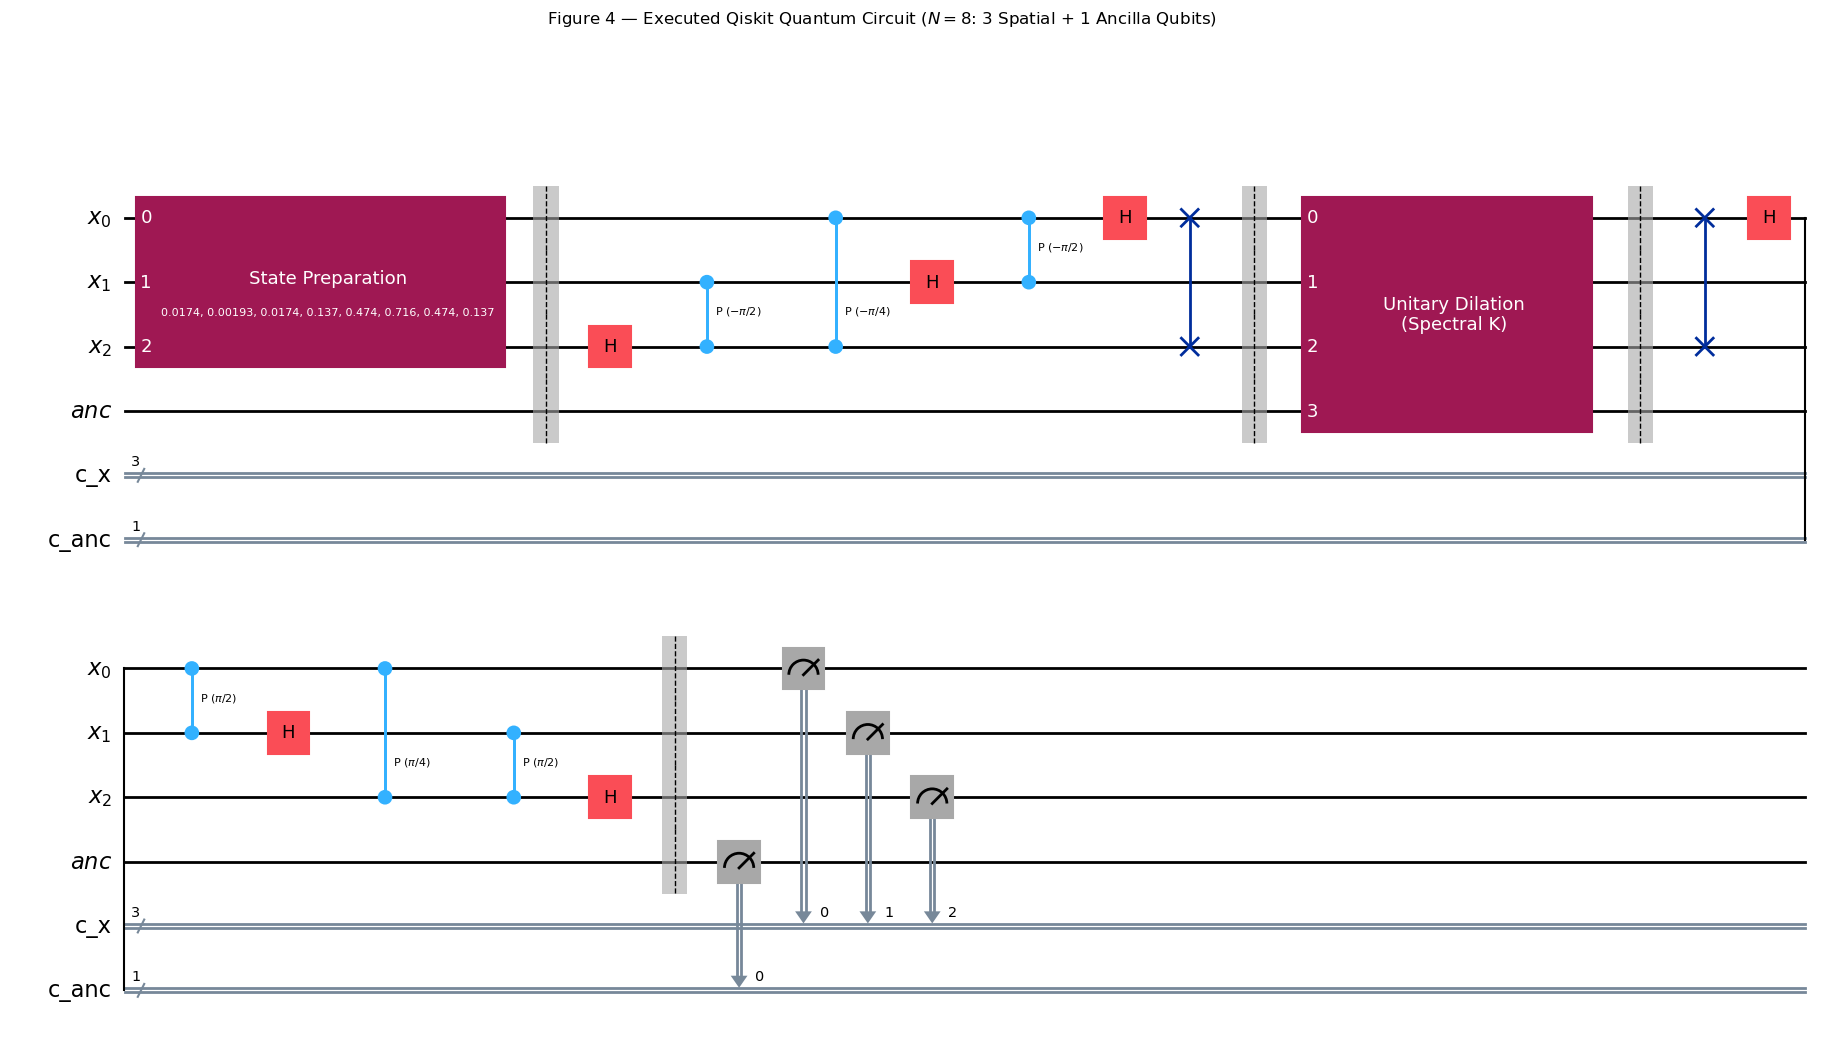

In [8]:
# Build the full 4-qubit Qiskit circuit (3 spatial qubits + 1 ancilla qubit)
q_space = QuantumRegister(n_qubits, "x")
q_anc = QuantumRegister(1, "anc")
c_space = ClassicalRegister(n_qubits, "c_x")
c_anc = ClassicalRegister(1, "c_anc")

qc_base = QuantumCircuit(q_space, q_anc, c_space, c_anc, name="QFT_DDE_Solver")
qc_base.prepare_state(psi0, q_space)
qc_base.barrier()
add_qft(qc_base, list(q_space), inverse_sign=True)
qc_base.barrier()
qc_base.append(UnitaryGate(U_dilation, label="Unitary Dilation\n(Spectral K)"), list(q_space) + list(q_anc))
qc_base.barrier()
add_qft(qc_base, list(q_space), inverse_sign=False)
qc_base.barrier()

# Measurement circuit executed in finite-shot Aer simulation and displayed in Figure 4
qc_meas = qc_base.copy()
qc_meas.measure(q_anc, c_anc)
qc_meas.measure(q_space, c_space)

# Figure 4 — Actual executed Qiskit quantum circuit
fig4 = qc_meas.draw("mpl", fold=26)
fig4.suptitle("Figure 4 — Executed Qiskit Quantum Circuit ($N=8$: 3 Spatial + 1 Ancilla Qubits)", fontsize=12, y=1.02)
fig4

Theoretical postselection P(0) = 0.65220918
Simulated   postselection P(0) = 0.65220918  (diff = 1.11e-16)
Recovered Qiskit QFT vs Classical FFT L_inf diff = 1.67e-16

Finite-shot run (50,000 shots): postselected 32,670 shots -> empirical P(0) = 0.65340
Chi-squared test vs ideal Born probabilities: chi2 = 3.894, p-value = 0.7919 (8 bins)


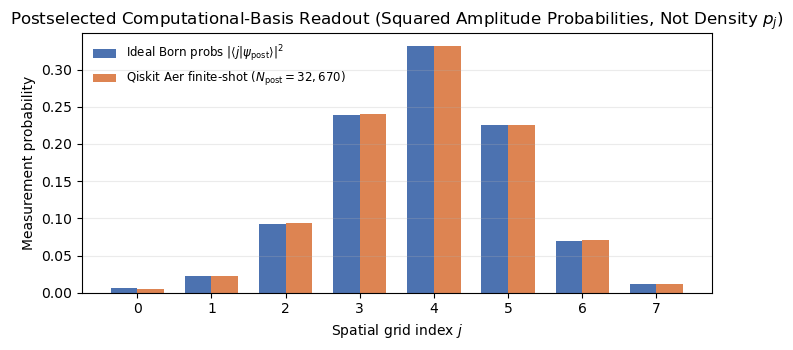

In [9]:
# 1) Ideal Statevector Simulation on Qiskit Aer (pre-measurement state)
qc_sv = qc_base.copy()
qc_sv.save_statevector()
sv_full = np.asarray(sim_sv.run(transpile(qc_sv, sim_sv, optimization_level=0)).result().get_statevector(qc_sv))

# Ancilla-|0> branch corresponds to indices 0..N-1 (ancilla qubit is MSB)
anc0_branch = sv_full[:N]
P0_sim = float(np.sum(np.abs(anc0_branch) ** 2))
P0_theory = float(np.linalg.norm(K @ psi_F_classical, ord=2) ** 2)

# Account for global phase, postselection normalization, alpha scaling, and ||p0||_2
peak_idx = int(np.argmax(np.abs(anc0_branch)))
global_phase = float(np.angle(anc0_branch[peak_idx]))
psi_post = (anc0_branch * np.exp(-1j * global_phase)) / np.sqrt(P0_sim)
p_qft = np.real(alpha * norm_p0 * np.sqrt(P0_sim) * psi_post)

qft_vs_fft_inf = np.max(np.abs(p_qft - p_fft))
print(f"Theoretical postselection P(0) = {P0_theory:.8f}")
print(f"Simulated   postselection P(0) = {P0_sim:.8f}  (diff = {abs(P0_theory - P0_sim):.2e})")
print(f"Recovered Qiskit QFT vs Classical FFT L_inf diff = {qft_vs_fft_inf:.2e}")

# 2) Finite-Shot Measurement Simulation on Qiskit Aer
sim_qasm = AerSimulator(seed_simulator=seed)
counts = sim_qasm.run(transpile(qc_meas, sim_qasm, optimization_level=0), shots=shots).result().get_counts()

# Postselect on shots where ancilla bit == '0' (bitstring format: '<c_anc> <c_x>')
post_counts = np.zeros(N, dtype=int)
for bitstr, cnt in counts.items():
    anc_bit, x_bits = bitstr.split()
    if anc_bit == "0":
        post_counts[int(x_bits, 2)] += cnt

n_post = int(post_counts.sum())
P0_emp = n_post / shots
emp_born_probs = post_counts / n_post
ideal_born_probs = np.abs(psi_post) ** 2
exp_counts = ideal_born_probs * n_post
keep_bins = exp_counts >= 5.0
if not keep_bins.all() and keep_bins.any():
    obs_chi2 = np.append(post_counts[keep_bins], post_counts[~keep_bins].sum())
    exp_chi2 = np.append(exp_counts[keep_bins], exp_counts[~keep_bins].sum())
else:
    obs_chi2, exp_chi2 = post_counts, exp_counts
chi2_stat, chi2_pval = chisquare(obs_chi2, f_exp=exp_chi2)

print(f"\nFinite-shot run ({shots:,} shots): postselected {n_post:,} shots -> empirical P(0) = {P0_emp:.5f}")
print(f"Chi-squared test vs ideal Born probabilities: chi2 = {chi2_stat:.3f}, p-value = {chi2_pval:.4f} ({len(obs_chi2)} bins)")

# Diagnostic plot of finite-shot postselected measurement statistics (squared amplitudes)
fig_shots, ax_s = plt.subplots(figsize=(7.2, 3.6))
bar_w = 0.36
ax_s.bar(j_modes - bar_w / 2, ideal_born_probs, width=bar_w, color="#4c72b0", label="Ideal Born probs $|\\langle j|\\psi_{\\text{post}}\\rangle|^2$")
ax_s.bar(j_modes + bar_w / 2, emp_born_probs, width=bar_w, color="#dd8452", label=f"Qiskit Aer finite-shot ($N_{{\\text{{post}}}}={n_post:,}$)")
ax_s.set_title("Postselected Computational-Basis Readout (Squared Amplitude Probabilities, Not Density $p_j$)")
ax_s.set_xlabel("Spatial grid index $j$")
ax_s.set_ylabel("Measurement probability")
ax_s.set_xticks(j_modes if N <= 32 else j_modes[:: max(1, N // 16)])
ax_s.grid(axis="y", alpha=0.25)
ax_s.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

# 10. Final Comparison and Complexity Ledger

We now overlay the final $t = T$ probability densities from all four sources (Analytical wrapped Gaussian, Classical Direct FTCS, Classical FFT, and Qiskit QFT statevector) on the exact same spatial grid, and summarise the asymptotic computational complexities.

### Figure 5 — Error Ledger & Asymptotic Time Complexity

In Devereux & Datta (2025), the **Error Ledger** splits the total infinity-norm error budget $\epsilon = \epsilon_c + \epsilon_q$ into:
- **Classical discretisation error** $\epsilon_c = \|\mathbf{p}_{\text{direct}}(T) - \mathbf{p}_{\text{exact}}(T)\|_\infty$, which sets the required grid resolution via **Corollary 2** ($n_t \propto \epsilon_c^{-1}$ and $N = n_x^d \propto \epsilon_c^{-d/2}$).
- **Quantum readout error** $\epsilon_q = \|\tilde{\mathbf{p}}_{\text{meas}}(T) - \mathbf{p}_{\text{QFT}}(T)\|_\infty$ from finite-shot / amplitude-estimation extraction.

Plugging $(\epsilon_c, \epsilon_q)$ into **Theorems 7, 10, and 22** (Tables I & III of the paper) maps the error budget directly to asymptotic time complexity (omitting logarithmic factors in $\tilde{O}$):

| Method | Core evolution cost | Error-driven scaling (Thm 7, 10, 22) | 1D ($d=1$) | 3D ($d=3$) |
|---|---|---|---|---|
| **Method 1: Direct evolution** (Thm 7) | $O(n_t N)$ | $\tilde{O}\!\left(\dfrac{d^{d/2+3}T^{d/2+2}\zeta^{d/2+1}(aL+D)^{d+2}}{D^{d/2}\,\epsilon_c^{d/2+1}}\right)$ | $\tilde{O}(\epsilon_c^{-1.5})$ | $\tilde{O}(\epsilon_c^{-2.5})$ |
| **Method 2: Classical FFT** (Thm 10) | $O(N \log N)$ | $\tilde{O}\!\left(\dfrac{d^{d/2+1}T^{d/2}\zeta^{d/2}L^d(aL+D)^d}{D^{d/2}\,\epsilon_c^{d/2}}\right)$ | $\tilde{O}(\epsilon_c^{-0.5})$ | $\tilde{O}(\epsilon_c^{-1.5})$ |
| **Method 3: Quantum QFT** (Thm 22) | $O(\log^2 N)$ QFT + overhead | $\tilde{O}\!\left(\dfrac{d^{d/2+2}T^{d/2}\zeta^{d/4}(aL+D)^{d/2}}{\epsilon_c^{d/4}\,\epsilon_q}\right)$ | $\tilde{O}(\epsilon_c^{-0.25}\epsilon_q^{-1})$ | $\tilde{O}(\epsilon_c^{-0.75}\epsilon_q^{-1})$ |

#### Detailed Quantum QFT Cost Accounting
The $O(\log^2 N)$ QFT gate count is **only one subroutine** of the quantum algorithm. A complete accounting for the quantum solver must separately include:

| Quantum Solver Stage | Cost / Scaling Notes |
|---|---|
| **1. Initial state preparation** | $O(N)$ gates in general for an arbitrary $N$-vector; $O(\log N)$ only for efficiently integrable analytical distributions. |
| **2. QFT and inverse QFT** | $O(\log^2 N)$ elementary two-qubit gates ($O(\log N \log\log N)$ for approximate QFT). |
| **3. Ancilla-assisted diagonal operation** | Dense $2N \times 2N$ dilation here ($O(N^2)$ classical matrix build); $O(\log N + \log(1/\delta))$ coherent eigenvalue arithmetic + $O(N \log(n_t/\delta))$ precomputation in Devereux & Datta. |
| **4. Postselection or amplitude amplification** | $O(1/P(0))$ expected runs via direct postselection, or $O(1/\sqrt{P(0)}) = O(\|\mathcal{L}^{n_t}|p_0\rangle\|_2^{-1}) = O(n_t^{1/4})$ in 1D via amplitude amplification. |
| **5. Measurement and output extraction** | Reading out the full distribution up to $\infty$-norm error $\epsilon_q$ adds $\tilde{O}(1/\epsilon_q)$ repetitions via multidimensional amplitude estimation (not free like a single expectation value). |

**Important caveats:**
- The full quantum solver does **not** cost only $O(\log^2 N)$.
- This small $N = 8$ Qiskit circuit demonstration is an educational illustration of the Fourier-space algorithm and **is not evidence of a practical quantum speedup**: as Equation (1) of Devereux & Datta shows, Quantum QFT only beats Classical FFT at high dimension $d$ and strict total error budgets $\epsilon$ (illustrated for the paper's 3D finance benchmark in Figure 5).

=== Final Distribution Accuracy Summary (t = T) ===
Direct FTCS vs Analytical   : L_inf (eps_c) = 2.648047e-02
Classical FFT vs Analytical : L_inf         = 2.648047e-02
Qiskit QFT vs Analytical    : L_inf         = 2.648047e-02
Classical FFT vs Direct     : L_inf         = 9.436896e-16
Qiskit QFT vs Classical FFT : L_inf         = 1.665335e-16
Finite-shot Born error      : L_inf (eps_q) = 1.037819e-03
Combined Error Ledger       : eps = eps_c + eps_q = 2.751828e-02

=== Error-to-Time-Complexity Ledger (Corollary 2 & Theorems 7, 10, 22) ===
Corollary 2 bounds at eps_c=0.0265 : dx_max=0.1034 (used 0.5000), dt_max=0.0357 (used 0.0500)
Corollary 2 grid targets                : nx_theory=38.7 (used 8), nt_theory=42.1 (used 30)
  Method 1 (Direct FTCS, Thm 7)         : Grid nt*N =    240 ops  | Thm 7 (1D)  = 1.416e+03 ops
  Method 2 (Classical FFT, Thm 10)      : Grid N*log2N =  24 ops  | Thm 10 (1D) = 3.692e+01 ops
  Method 3 (Quantum QFT, Thm 22)        : QFT core = 9 gates, full AA+reado

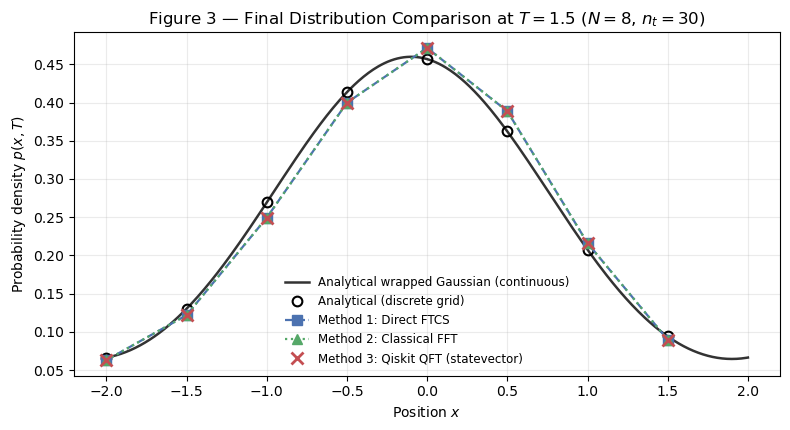

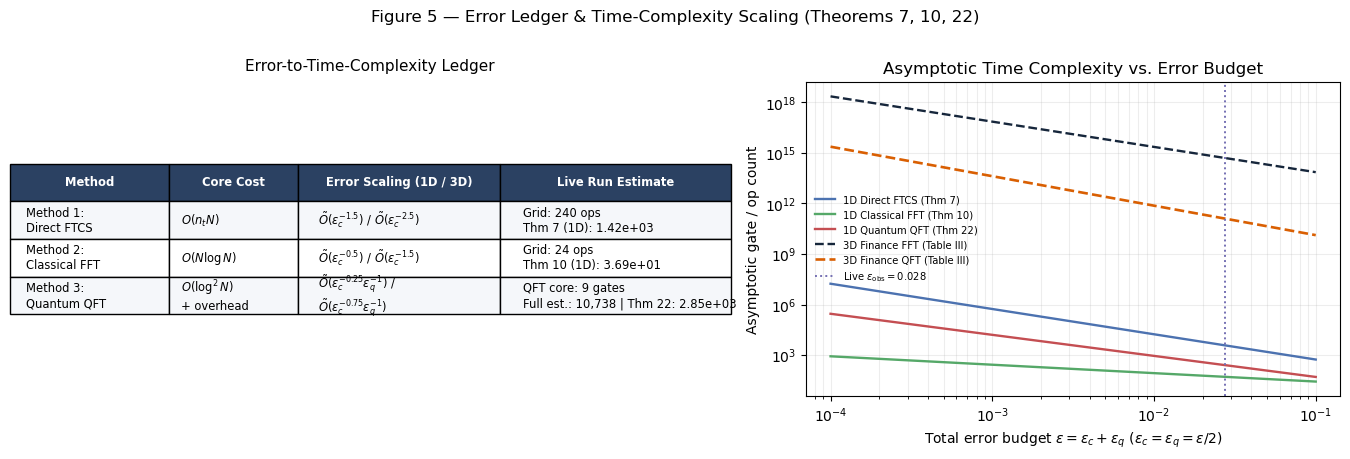

In [10]:
# Summary error metrics across all methods
eps_c_obs = float(np.max(np.abs(p_direct - p_exact_T)))
eps_q_obs = float(np.max(np.abs(emp_born_probs - ideal_born_probs)))
eps_total_obs = eps_c_obs + eps_q_obs

print("=== Final Distribution Accuracy Summary (t = T) ===")
print(f"Direct FTCS vs Analytical   : L_inf (eps_c) = {eps_c_obs:.6e}")
print(f"Classical FFT vs Analytical : L_inf         = {np.max(np.abs(p_fft - p_exact_T)):.6e}")
print(f"Qiskit QFT vs Analytical    : L_inf         = {np.max(np.abs(p_qft - p_exact_T)):.6e}")
print(f"Classical FFT vs Direct     : L_inf         = {np.max(np.abs(p_fft - p_direct)):.6e}")
print(f"Qiskit QFT vs Classical FFT : L_inf         = {np.max(np.abs(p_qft - p_fft)):.6e}")
print(f"Finite-shot Born error      : L_inf (eps_q) = {eps_q_obs:.6e}")
print(f"Combined Error Ledger       : eps = eps_c + eps_q = {eps_total_obs:.6e}")

# Corollary 2 theoretical step bounds & Theorem 7/10/22 complexity ledger
d_1d, zeta_1d = 1, 1.0
poly_1d = 3.0 * (a ** 2) * (L_half ** 2) + 8.0 * a * D * L_half + 4.0 * (D ** 2)
dx_max_cor2 = float(np.sqrt((12.0 * eps_c_obs * D) / (T * d_1d * zeta_1d * poly_1d)))
dt_max_cor2 = float((6.0 * eps_c_obs) / (T * (d_1d ** 2) * zeta_1d * poly_1d))
nt_theory_cor2 = float((T ** 2) * (d_1d ** 2) * zeta_1d * poly_1d / (6.0 * eps_c_obs))
nx_theory_cor2 = float(np.sqrt((T * d_1d * zeta_1d * (L_half ** 2) * poly_1d) / (3.0 * eps_c_obs * D)))

def thm_complexity_prefactors(T_val, L_val, a_val, D_val, d_val, zeta_val=1.0):
    """Asymptotic complexity prefactors from Theorems 7, 10, and 22 (Devereux & Datta Tables I & III)."""
    aLD = a_val * L_val + D_val
    return {
        "direct": (d_val ** (d_val / 2.0 + 3.0)) * (T_val ** (d_val / 2.0 + 2.0)) * (zeta_val ** (d_val / 2.0 + 1.0)) * (aLD ** (d_val + 2.0)) / (D_val ** (d_val / 2.0)),
        "fft": (d_val ** (d_val / 2.0 + 1.0)) * (T_val ** (d_val / 2.0)) * (zeta_val ** (d_val / 2.0)) * (L_val ** d_val) * (aLD ** d_val) / (D_val ** (d_val / 2.0)),
        "qft": (d_val ** (d_val / 2.0 + 2.0)) * (T_val ** (d_val / 2.0)) * (zeta_val ** (d_val / 4.0)) * (aLD ** (d_val / 2.0)),
    }

pref_1d = thm_complexity_prefactors(T, L_half, a, D, d_val=1, zeta_val=1.0)
pref_3d_fin = thm_complexity_prefactors(5000.0, 10.0, 0.2366, 0.2455, d_val=3, zeta_val=1.0)

# Live grid-level operation / gate estimates and Theorem 7 / 10 / 22 error-budget estimates
ops_direct_grid = int(nt * N)
ops_fft_grid = int(N * n_qubits)
gates_qft_core = int(n_qubits ** 2)
ops_qft_full_grid = float((n_qubits ** 2) / (np.sqrt(P0_sim) * max(eps_q_obs, 1e-6)))

thm7_1d_obs = float(pref_1d["direct"] / (eps_c_obs ** 1.5))
thm10_1d_obs = float(pref_1d["fft"] / (eps_c_obs ** 0.5))
thm22_1d_obs = float(pref_1d["qft"] / ((eps_c_obs ** 0.25) * max(eps_q_obs, 1e-6)))

print("\n=== Error-to-Time-Complexity Ledger (Corollary 2 & Theorems 7, 10, 22) ===")
print(f"Corollary 2 bounds at eps_c={eps_c_obs:.4f} : dx_max={dx_max_cor2:.4f} (used {dx:.4f}), dt_max={dt_max_cor2:.4f} (used {dt:.4f})")
print(f"Corollary 2 grid targets                : nx_theory={nx_theory_cor2:.1f} (used {N}), nt_theory={nt_theory_cor2:.1f} (used {nt})")
print(f"  Method 1 (Direct FTCS, Thm 7)         : Grid nt*N = {ops_direct_grid:>6,d} ops  | Thm 7 (1D)  = {thm7_1d_obs:.3e} ops")
print(f"  Method 2 (Classical FFT, Thm 10)      : Grid N*log2N = {ops_fft_grid:>3d} ops  | Thm 10 (1D) = {thm10_1d_obs:.3e} ops")
print(f"  Method 3 (Quantum QFT, Thm 22)        : QFT core = {gates_qft_core} gates, full AA+readout ~ {ops_qft_full_grid:,.0f} | Thm 22 (1D) = {thm22_1d_obs:.3e} ops")

# Figure 3 — Final distribution comparison
fig3, ax3 = plt.subplots(figsize=(8.0, 4.4))
ax3.plot(x_fine, p_exact_T_fine, "k-", lw=1.8, alpha=0.8, label="Analytical wrapped Gaussian (continuous)")
ax3.plot(x, p_exact_T, "ko", markersize=7, fillstyle="none", mew=1.5, label="Analytical (discrete grid)")
ax3.plot(x, p_direct, "s--", markersize=6.5, lw=1.6, color="#4c72b0", label="Method 1: Direct FTCS")
ax3.plot(x, p_fft, "^:", markersize=7, lw=1.6, color="#55a868", label="Method 2: Classical FFT")
ax3.plot(x, p_qft, "x", markersize=8, mew=2.0, color="#c44e52", label="Method 3: Qiskit QFT (statevector)")
ax3.set_title(f"Figure 3 — Final Distribution Comparison at $T = {T}$ ($N = {N}$, $n_t = {nt}$)")
ax3.set_xlabel("Position $x$")
ax3.set_ylabel("Probability density $p(x, T)$")
ax3.grid(alpha=0.25)
ax3.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

# Figure 5 — Error-to-Time-Complexity Ledger & Asymptotic Scaling
fig5, (ax5, ax5_scale) = plt.subplots(1, 2, figsize=(13.6, 4.5), gridspec_kw={"width_ratios": [1.35, 1.0]})
ax5.axis("off")
ledger_rows = [
    ["Method 1:\nDirect FTCS", "$O(n_t N)$", "$\\tilde{O}(\\epsilon_c^{-1.5})$ / $\\tilde{O}(\\epsilon_c^{-2.5})$", f"Grid: {ops_direct_grid:,} ops\nThm 7 (1D): {thm7_1d_obs:.2e}"],
    ["Method 2:\nClassical FFT", "$O(N \\log N)$", "$\\tilde{O}(\\epsilon_c^{-0.5})$ / $\\tilde{O}(\\epsilon_c^{-1.5})$", f"Grid: {ops_fft_grid:,} ops\nThm 10 (1D): {thm10_1d_obs:.2e}"],
    ["Method 3:\nQuantum QFT", "$O(\\log^2 N)$\n+ overhead", "$\\tilde{O}(\\epsilon_c^{-0.25}\\epsilon_q^{-1})$ /\n$\\tilde{O}(\\epsilon_c^{-0.75}\\epsilon_q^{-1})$", f"QFT core: {gates_qft_core} gates\nFull est.: {ops_qft_full_grid:,.0f} | Thm 22: {thm22_1d_obs:.2e}"]
]
tbl = ax5.table(
    cellText=ledger_rows,
    colLabels=["Method", "Core Cost", "Error Scaling (1D / 3D)", "Live Run Estimate"],
    cellLoc="left",
    loc="center",
    colWidths=[0.22, 0.18, 0.28, 0.32]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.3)
tbl.scale(1.0, 2.5)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor("#2b4162")
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor("#f5f7fa" if r % 2 == 1 else "#ffffff")
ax5.set_title("Error-to-Time-Complexity Ledger", fontsize=11, pad=8)

eps_vals = np.logspace(-4, -1, 60)
eps_c_split = 0.5 * eps_vals
eps_q_split = 0.5 * eps_vals
ax5_scale.loglog(eps_vals, pref_1d["direct"] / (eps_c_split ** 1.5), "-", lw=1.7, color="#4c72b0", label="1D Direct FTCS (Thm 7)")
ax5_scale.loglog(eps_vals, pref_1d["fft"] / (eps_c_split ** 0.5), "-", lw=1.7, color="#55a868", label="1D Classical FFT (Thm 10)")
ax5_scale.loglog(eps_vals, pref_1d["qft"] / ((eps_c_split ** 0.25) * eps_q_split), "-", lw=1.7, color="#c44e52", label="1D Quantum QFT (Thm 22)")
ax5_scale.loglog(eps_vals, pref_3d_fin["fft"] / (eps_c_split ** 1.5), "--", lw=1.7, color="#16263b", label="3D Finance FFT (Table III)")
ax5_scale.loglog(eps_vals, pref_3d_fin["qft"] / ((eps_c_split ** 0.75) * eps_q_split), "--", lw=1.9, color="#d95f02", label="3D Finance QFT (Table III)")
ax5_scale.axvline(eps_total_obs, color="#7570b3", ls=":", lw=1.4, label=f"Live $\\epsilon_{{\\text{{obs}}}}={eps_total_obs:.3f}$")
ax5_scale.set_title("Asymptotic Time Complexity vs. Error Budget")
ax5_scale.set_xlabel(r"Total error budget $\epsilon = \epsilon_c + \epsilon_q$ ($\epsilon_c = \epsilon_q = \epsilon/2$)")
ax5_scale.set_ylabel("Asymptotic gate / op count")
ax5_scale.grid(True, which="both", alpha=0.22)
ax5_scale.legend(frameon=False, fontsize=7.2, loc="best")

fig5.suptitle("Figure 5 — Error Ledger & Time-Complexity Scaling (Theorems 7, 10, 22)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

# 11. Conclusions and Limitations

### Key Takeaways
1. **Shared mathematics across all three solvers:** Periodic boundary conditions and constant coefficients make the FTCS evolution matrix $L$ circulant, so direct time stepping ($L^{n_t}\mathbf{p}_0$), classical FFT diagonalisation ($F^\dagger\Lambda^{n_t}F\mathbf{p}_0$), and the Qiskit QFT circuit all solve the **identical discrete problem** and agree to machine precision ($\sim 10^{-15}$).
2. **From classical to quantum diagonalisation:** QFT replaces the $O(N \log N)$ classical transform with $O(\log^2 N)$ quantum gates on $n = \log_2 N$ qubits, while non-unitary damping ($|\lambda_j^{n_t}| \le 1$) is handled via an ancilla-assisted unitary dilation and postselection.

### Practical Limitations
- **Full quantum cost exceeds $O(\log^2 N)$:** Initial state preparation, coherent eigenvalue circuits, postselection / amplitude amplification overhead ($P(0)$ shrinks as diffusion smooths the state), and multidimensional distribution readout ($\tilde{O}(1/\epsilon_q)$) dominate total complexity.
- **Readout distinction:** Computational-basis shots sample squared amplitudes $|\psi_j|^2$ rather than the signed density $p_j$ directly.
- **Educational scale:** Our $N = 8$ Qiskit demonstration confirms algorithmic correctness, not a practical quantum advantage.

The final cell below verifies every validation requirement programmatically.

In [11]:
# Final Automated Validation Checklist
assert np.isclose(np.sum(p0) * dx, 1.0, atol=1e-12), "Initial p0 is not normalised!"
assert mu_T < x0 if a > 0 else mu_T >= x0, "Analytical drift sign convention mismatch!"
assert min(c0, c_plus, c_minus) >= 0.0 and np.isclose(c0 + c_plus + c_minus, 1.0, atol=1e-12), "FTCS stability/positivity failed!"
assert diffusion_cfl <= 1.0 + 1e-12, "CFL condition violated!"
assert np.max(np.abs(p_fft - p_direct)) < 1e-12, "Direct and FFT solutions disagree!"
assert diag_check_err < 1e-12, "Eigenvalues do not diagonalise L!"
assert qft_vs_fft_err < 1e-12 and roundtrip_err < 1e-12, "QFT/IQFT qubit ordering or convention mismatch!"
assert unitarity_err < 1e-12 and block0_err < 1e-12, "Unitary dilation block check failed!"
assert abs(P0_theory - P0_sim) < 1e-12, "Postselection probability mismatch!"
assert np.max(np.abs(p_qft - p_fft)) < 1e-12, "Postselected Qiskit state disagrees with classical FFT!"
assert chi2_pval > 0.01, f"Finite-shot chi2 p-value unexpectedly low: {chi2_pval}"
assert abs(P0_emp - P0_sim) < 4.0 * np.sqrt(P0_sim * (1.0 - P0_sim) / shots), "Empirical P(0) outside 4-sigma!"

print("ALL 11 VALIDATION CHECKS PASSED!")

ALL 11 VALIDATION CHECKS PASSED!
